# 05. Адаптация и персонализация

**Вопрос этапа:** какую часть потерь при переходе на новый день и нового человека
(этапы 3–4: LDA 87 → 48 / 44 %, TCN 89 → 52 / 55 %) можно вернуть **без меток**, какую — **короткой калибровкой**,
и сколько секунд она стоит пользователю?

Цель — фраза вида «N секунд калибровки при надевании дают +X п.п., дальше плато».

Эксперименты (`python run.py --config configs/<имя>.yaml`), все на 10 dev-участниках:
`adapt_lda_dev` (методы × бюджет), `adapt_lda_passes_dev` (повторения или секунды), `adapt_tcn_dev`;
после выбора настроек — один прогон на test. Код: `src/adapt.py`, `run_adapt_lda` / `run_adapt_tcn` в `run.py`.
Ноутбук ничего не обучает: он объясняет методы и читает готовые результаты.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import yaml
from IPython.display import Image, display

from data import N_GESTURES
pd.set_option("display.width", 160)


def load(name: str) -> dict | None:
    # Result file results/<name>.json, or None with a hint if the experiment has not been run yet.
    path = ROOT / "results" / f"{name}.json"
    if not path.exists():
        print(f"Результатов ещё нет: python run.py --config configs/{name}.yaml")
        return None
    return json.loads(path.read_text(encoding="utf-8"))

## 1. Что ломается при переносе

**Термины:**
- **Распределение признаков** $p(x)$ — где в пространстве признаков лежат окна: облака точек, по одному на жест.
- **Covariate shift** (сдвиг входного распределения) — $p(x)$ в новой сессии другое, а правило «какой жест какой
  картине соответствует» $p(y \mid x)$ по смыслу то же: жесты те же, изменилось то, как они выглядят в сигнале.
- **Адаптация** — подстройка модели под новую сессию по её собственным данным. **Без меток** — используем только сигнал,
  не зная, какой жест выполнялся. **С метками (калибровка)** — просим пользователя сделать известные жесты.

**Что мы уже знаем о сдвиге:**
- Между днями (этапы 2–3) главное — **общий сдвиг**: все облака жестов уезжают вместе (2,9 из 3,2 единиц
  сдвига центра). Физически — другое сопротивление контакта кожа–электрод, другое положение браслета:
  сигнал на канале умножается на свой коэффициент $k_c$. После логарифма амплитудных признаков
  умножение становится сложением: $\log(k_c \cdot \text{RMS}) = \log \text{RMS} + \log k_c$ — **сдвиг**, одинаковый
  для всех жестов. Такой сдвиг можно оценить по новой сессии без меток.
- Между людьми, кроме сдвига уровня, другая **форма**: другая анатомия, электрод над другой мышцей,
  другая манера выполнять жест. Общий сдвиг это не опишет — нужен «свой» центр для каждого жеста, а значит метки.

## 2. Адаптация без меток

### 2.1. LDA: нормализация по сессии
Из признаков каждого окна вычитаем средний вектор признаков **той же сессии** по опорным окнам:
$$\tilde f = f - \overline{f}_{\text{сессия}}^{\,\text{опорные окна}}.$$
Это делается **для каждой сессии**, в том числе обучающих (каждая — по своим опорным окнам). Тогда модель учится
на «выровненных» данных и в новой сессии видит их в том же виде. Информация между сессиями не переносится.

Два варианта опорных окон:
- **`rest` — первые 5 с покоя.** Самое дешёвое: браслет надели, рука 5 с лежит спокойно.
  Но в покое канал показывает **шум** (контакт, электроника, фоновый тонус), а не работу мышц.
  На этапе 2 сдвиг шума покоя между днями (2–4 дБ) не совпадал со сдвигом сигнала жестов (1–3 дБ) и шёл из других причин.
- **`unlabeled` — окна всех жестов без меток.** Первые *s* секунд каждого жеста из калибровочных попыток,
  метки не используются. В продукте это аналог «первых минут обычного использования». Оговорка: у нас смесь жестов
  **сбалансирована** (все 17 поровну), в жизни пользователь делает одни жесты чаще других — оценка оптимистичная.

### 2.2. TCN: масштаб входа и AdaBN
- **`input_scale`** — 12 чисел `scale` (SD каждого канала, на которые сеть делит вход) пересчитываются
  по сигналу новой сессии. Это поправка на коэффициент $k_c$ каждого канала, аналог нормализации у LDA.
- **BatchNorm** внутри сети: $\text{BN}(z) = \gamma \cdot \dfrac{z - \mu}{\sigma} + \beta$, где $\mu, \sigma$ — среднее
  и SD этого внутреннего канала, **накопленные на обучающих данных**, а $\gamma, \beta$ — обучаемые веса.
- **AdaBN** (Li et al., 2016): веса не трогаем, а $\mu, \sigma$ во всех 12 слоях BatchNorm пересчитываем по данным
  новой сессии. Идея: всё, чем домены отличаются, частично сидит в статистиках внутренних каналов.
  У нас `adabn` = `input_scale` + пересчёт BatchNorm. Масштаб входа нужен отдельно: в остаточных блоках сигнал идёт
  ещё и в обход BatchNorm (через $x + f(x)$), и общий множитель на входе одним BatchNorm не снимается.

Для сети нормализацию по покою не делаем: её пришлось бы встроить и в обучение (каждую обучающую сессию делить
на её покой), а сеть обучена на других статистиках — смешивать нельзя.

## 3. Калибровка с метками

Пользователь выполняет каждый из 17 жестов по *s* секунд, и мы знаем, какой жест был.

### 3.1. LDA: калибровка центров (`means`)
LDA описывает каждый жест **центром** $\mu_c$ и общей для всех жестов **ковариацией** $\Sigma$ (формой облака),
и относит окно к жесту с наибольшим
$$\delta_c(x) = x^\top \Sigma^{-1}\mu_c - \tfrac12\,\mu_c^\top \Sigma^{-1}\mu_c + \log \pi_c.$$

Метод — **два шага подряд** на одних и тех же калибровочных окнах:
1. **Нормализация без меток** (как `unlabeled`): из всех окон новой сессии вычитается их среднее по калибровочным
   окнам. Это снимает общий сдвиг **целиком**.
2. **Смешивание центров** (нужны метки): уже в выровненных координатах
$$\mu_c^{\text{new}} = a\,\mu_c^{\text{калибр}} + (1-a)\,\mu_c^{\text{обуч}},\qquad a = \frac{s}{s + \tau}.$$
   Ковариация $\Sigma$ — из обучения.

Зачем смешивать, а не заменять. Старый выровненный центр **смещён** на свою часть сдвига жеста, но посчитан по тысячам
окон. Новый центр не смещён, но **шумит**: при 1 с это 13 перекрывающихся окон одного повторения, а центр жеста гуляет
между повторениями даже внутри сессии (этап 3). $\tau$ (в секундах) задаёт, кому доверять: $\tau = 0$ — полностью
заменить, $\tau = 5$ — при 1 с $a = 1/6$, при 5 с пополам. Это сжатие шумной оценки к априорной (shrinkage).

При $\tau = 0$ шаг 1 ни на что не влияет: старые центры выброшены, а общий сдвиг одинаково двигает калибровочные центры
и тестовые окна. Вычитание **старого** среднего делает и `StandardScaler` в варианте «без адаптации» — это просто
перенос начала координат; сдвиг снимает только вычитание **своего** среднего новой сессии.

Ковариация из обучения — **допущение**: «форма облаков меняется мало, а 1830 чисел по нескольким секундам не оценить».
Результаты (раздел 6) показали, что при достаточной калибровке оно неверно.

- **`scratch`** — для сравнения: своя LDA, обученная **только** на калибровке, без общей модели. Отвечает на вопрос
  этапа 4: что лучше — общая модель с подстройкой или персональная модель с нуля при тех же секундах?

### 3.2. TCN: дообучение головы или всей сети
- **Голова** (`head`) — последний слой 64 → 17, всего 1105 весов: аналог замены центров у LDA. Мало параметров —
  мало риск переобучиться на нескольких секундах.
- **Вся сеть** (`full`) — все 152 тыс. весов с маленьким шагом (0,0001 против 0,001 при обучении). Может подстроить
  и сами признаки, но легче переобучается.
- В обоих случаях сначала AdaBN по тем же калибровочным данным, а при дообучении статистики BatchNorm заморожены:
  мини-батч из нескольких кусков одной сессии дал бы шумные оценки. 200 шагов по 64 случайных куска.

## 4. Протокол и цена для пользователя

Каждая **целевая сессия** (её базовая модель не видела) делится по попыткам:

| попытки | роль |
|---|---|
| 1–3 | **калибровочный запас**: отсюда берутся данные для адаптации (с метками или без) |
| 4–7 | **тест**: одинаковый для всех методов и бюджетов, поэтому все числа сравнимы |

Попытки записаны по порядку: попытка 1 — первый проход по всем жестам после надевания. Значит, калибровка из попыток
1–3 — это действительно начало сессии, как в продукте.

| эксперимент | базовая модель | целевые сессии |
|---|---|---|
| E2, новый день | своя сессия 1 | сессии 2 и 3 того же человека |
| E3, новый человек | 8 других dev-людей (те же 5 фолдов, что у TCN на этапе 4) | все 3 сессии двух отложенных |

В E3 каждая сессия нового человека адаптируется отдельно: это три разных надевания.

**Отличия от этапов 3–4:** тест — только попытки 4–7, а LDA в E3 учится на 8 людях, а не на 9.
Поэтому «без адаптации» здесь будет немного отличаться от прежних чисел.

**Бюджет** — «P × S»: первые S секунд каждого жеста в каждой из первых P попыток (P **проходов** по всем 17 жестам).
В `adapt_lda_dev` бюджет растёт самым быстрым способом: 1, 2, 5 с — начало попытки 1 (1×1, 1×2, 1×5), 10 и 15 с —
попытки 1–2 и 1–3 целиком (2×5, 3×5). В `adapt_lda_passes_dev` — вся сетка P = 1, 2, 3 × S = 1, 2, 5 с (раздел 7).
Время пользователя — 17 × P × S секунд удержания. Таблица ниже — для `adapt_lda_dev`.

In [2]:
cfg = yaml.safe_load((ROOT / "configs" / "adapt_lda_dev.yaml").read_text(encoding="utf-8"))
rows = []
for s in cfg["budgets_s"]:
    n = N_GESTURES * int(np.ceil(s / 5))          # contractions: a partial trial is still one contraction
    rows.append({"секунд на жест, s": s,
                 "откуда": "начало попытки 1" if s <= 5 else f"попытки 1–{s // 5} целиком",
                 "удержание, с (17 × s)": N_GESTURES * s,
                 "с паузами 10 с (протокол GRABMyo), мин": round((N_GESTURES * s + 10 * n) / 60, 1),
                 "с паузами 2 с, мин": round((N_GESTURES * s + 2 * n) / 60, 1)})
display(pd.DataFrame(rows).set_index("секунд на жест, s"))

,откуда,"удержание, с (17 × s)","с паузами 10 с (протокол GRABMyo), мин","с паузами 2 с, мин"
"секунд на жест, s",,,,
1,начало попытки 1,17,3.1,0.8
2,начало попытки 1,34,3.4,1.1
5,начало попытки 1,85,4.2,2.0
10,попытки 1–2 целиком,170,8.5,4.0
15,попытки 1–3 целиком,255,12.8,6.0


**Как читать:** по оси X на графиках ниже — **удержание** (17 × *s*), это нижняя оценка. Реальное время больше
на паузы между жестами. Даже минимальный бюджет — 1 с на жест — это 17 жестов подряд: меньше минуты с короткими
паузами, около трёх минут с паузами как в GRABMyo.

## 5. Гипотезы до запуска

Записаны до запуска экспериментов (`reports/notes.md`); подробно —
в разделах 2–3 (покой может не сработать; без меток помогает между днями сильнее;
ковариация меняется мало; общая модель + калибровка лучше своей модели с нуля).

## 6. Результаты: LDA

Таблицы: в ячейке — медиана balanced accuracy по 10 участникам, в скобках — медиана **попарного** выигрыша
над «без адаптации» (по каждому человеку отдельно) и у скольких участников выигрыш положительный.
Столбцы — время пользователя в секундах.

finished 2026-10-27T15:27:07


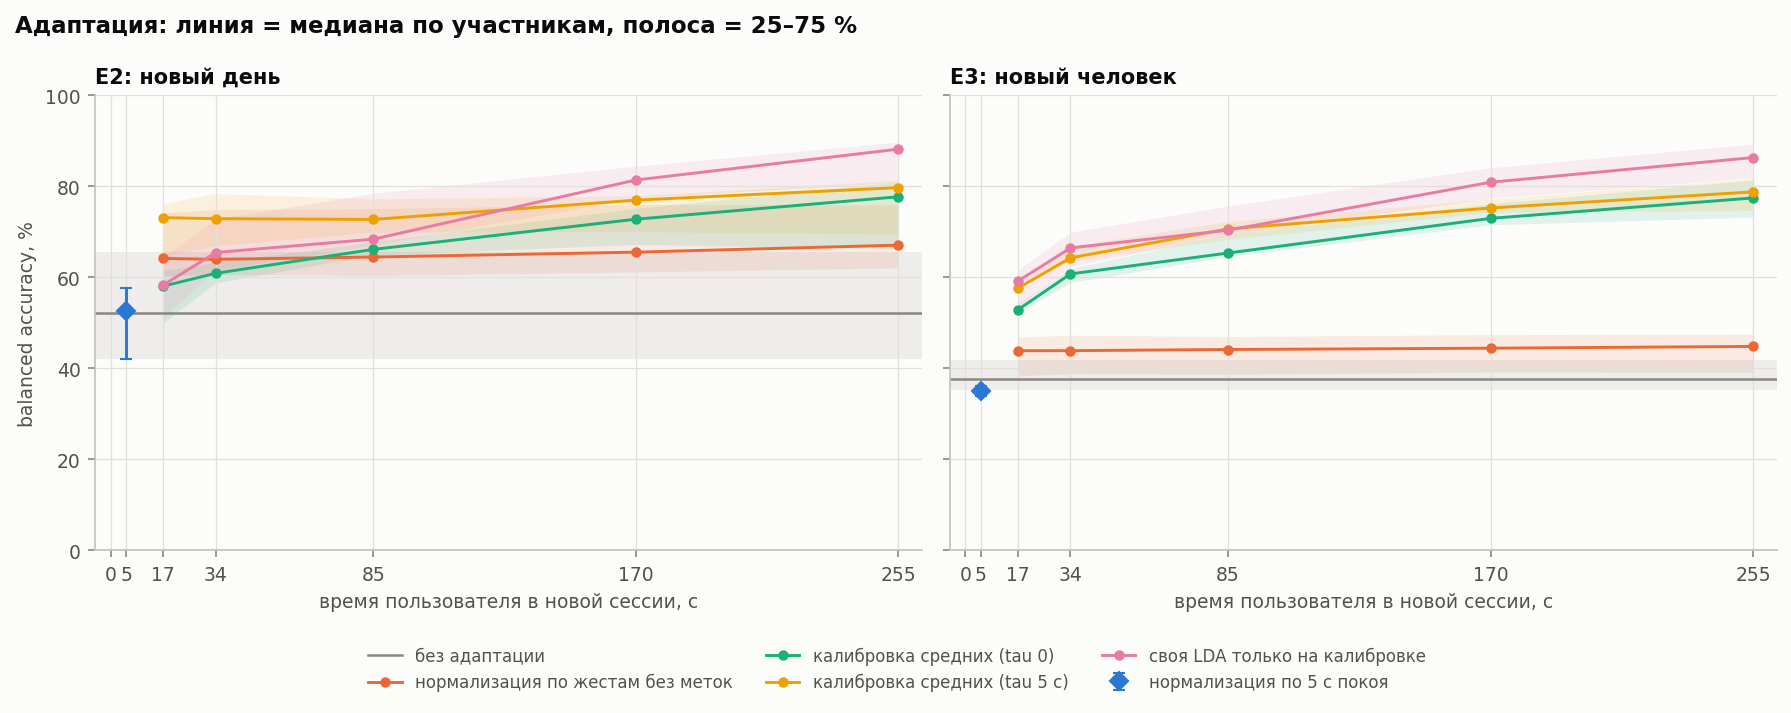

E2


,0 с,5 с,17 с,34 с,85 с,170 с,255 с
method,,,,,,,
none,52.2,,,,,,
rest,,52.6 (-2.6; 4/10),,,,,
unlabeled,,,64.2 (+11.3; 10/10),64.0 (+11.5; 10/10),64.5 (+11.7; 10/10),65.5 (+12.2; 10/10),67.1 (+13.7; 10/10)
means,,,58.1 (+0.1; 5/10),60.9 (+5.4; 7/10),66.1 (+8.9; 9/10),72.8 (+13.1; 10/10),77.7 (+15.1; 10/10)
means_tau5,,,73.1 (+15.2; 10/10),72.9 (+14.9; 10/10),72.7 (+15.8; 10/10),77.0 (+16.2; 10/10),79.7 (+18.0; 10/10)
scratch,,,58.3 (+4.7; 6/10),65.5 (+8.1; 8/10),68.4 (+15.9; 9/10),81.4 (+25.7; 10/10),88.2 (+30.0; 10/10)


E3


,0 с,5 с,17 с,34 с,85 с,170 с,255 с
method,,,,,,,
none,37.7,,,,,,
rest,,35.1 (-2.3; 1/10),,,,,
unlabeled,,,43.9 (+4.8; 10/10),43.9 (+5.2; 10/10),44.1 (+5.2; 10/10),44.4 (+5.7; 10/10),44.8 (+5.8; 10/10)
means,,,52.9 (+16.3; 10/10),60.7 (+24.1; 10/10),65.3 (+28.2; 10/10),73.0 (+36.5; 10/10),77.5 (+39.0; 10/10)
means_tau5,,,57.6 (+20.1; 10/10),64.3 (+27.2; 10/10),70.6 (+32.6; 10/10),75.2 (+38.6; 10/10),78.8 (+39.9; 10/10)
scratch,,,59.2 (+20.7; 10/10),66.5 (+29.1; 10/10),70.4 (+34.5; 10/10),80.9 (+42.8; 10/10),86.3 (+47.1; 10/10)


In [3]:
def tables(res: dict, order: list[str]) -> None:
    # Median balanced accuracy (paired median gain over `none`; participants with a gain) per method x cost.
    s = pd.DataFrame(res["summary"])
    s["cell"] = [f"{100 * r.median:.1f} ({100 * r.gain_median:+.1f}; {r.n_better}/{r.n})"
                 if r.method != "none" else f"{100 * r.median:.1f}" for r in s.itertuples()]
    for e, g in s.groupby("experiment"):
        t = g.pivot(index="method", columns="cost_s", values="cell").reindex(order)
        t.columns = [f"{c:g} с" for c in t.columns]
        print(e)
        display(t.fillna(""))


res_lda = load("adapt_lda_dev")
if res_lda:
    print("finished", res_lda["finished"])
    for f in res_lda["figures"]:
        display(Image(ROOT / f))
    tables(res_lda, list(res_lda["config"]["methods"]))

### Попарные сравнения

Разность двух методов по каждому участнику (п.п.): медиана и у скольких из 10 первый метод лучше.

In [ ]:
def paired(res: dict, a: tuple[str, str], b: tuple[str, str]) -> pd.DataFrame:
    # Per experiment: median over participants of method a - method b (balanced accuracy, p.p.) and wins of a.
    # a, b = (method, budget label), e.g. ("means_tau5", "1x1"); budget "0" for methods without a budget.
    pp = pd.DataFrame(res["per_participant"])
    if "budget" not in pp:                       # results written before budgets got labels
        pp["budget"] = [f"{1 if s <= 5 else int(s // 5)}x{min(s, 5):g}" if s else "0" for s in pp.budget_s]
    w = pp.pivot_table(index=["experiment", "participant"], columns=["method", "budget"], values="bal_acc")
    d = 100 * (w[a] - w[b])
    return pd.DataFrame({"медиана, п.п.": d.groupby("experiment").median().round(1),
                         "лучше у": d.groupby("experiment").apply(lambda v: f"{int((v > 0).sum())}/{len(v)}")})


if res_lda:
    comparisons = {
        "жесты без меток − без адаптации (1×1)": (("unlabeled", "1x1"), ("none", "0")),
        "покой 5 с − без адаптации": (("rest", "0"), ("none", "0")),
        "центры τ=0 − без меток (1×1)": (("means", "1x1"), ("unlabeled", "1x1")),
        "центры τ=5 − центры τ=0 (1×1)": (("means_tau5", "1x1"), ("means", "1x1")),
        "центры τ=5 − своя с нуля (1×1)": (("means_tau5", "1x1"), ("scratch", "1x1")),
        "центры τ=5 − своя с нуля (3×5)": (("means_tau5", "3x5"), ("scratch", "3x5")),
        "центры τ=0 − своя с нуля (3×5): те же центры, разная Σ": (("means", "3x5"), ("scratch", "3x5")),
    }
    display(pd.concat({k: paired(res_lda, *v) for k, v in comparisons.items()}).unstack("experiment"))

### Что показали результаты LDA

**1. Покой как опора нормализации не работает** — в среднем хуже, чем ничего, и непредсказуемо: у одних сессий
точность падает на 15–20 п.п. (24/s2 48 → 27, 35/s3 62 → 40), у других растёт (22, 31). Гипотеза подтвердилась:
в покое канал показывает шум, и его сдвиг не совпадает со сдвигом сигнала жестов. Ярче всего у участника 24:
его покой меняется из-за сетевой наводки (этап 2), и вычитается не тот вектор.

**2. Жесты без меток: +11 п.п. между днями, +5 между людьми, у всех 10.** Кривая плоская — 1 с на жест (17 с)
хватает, чтобы оценить среднее. Но закрыта лишь треть разрыва E1–E2 (36 п.п. → 24): своя часть сдвига каждого жеста
(~1,4 единицы) сравнима с расстоянием между соседними жестами (2,3–2,9). Облака встают на место, но каждое со своим
смещением. Оценка оптимистична: смесь жестов в калибровке сбалансирована.

**3. Смешивать центры лучше, чем заменять.** При 1 с полная замена (τ = 0) в E2 хуже, чем оставить старые выровненные
центры, у всех 10 (−9 п.п.): шум центра одного повторения больше смещения старого. В E3 наоборот (+12): центры чужих
людей смещены сильно. τ = 5 лучше τ = 0 везде; в E2 при 17 с он даёт **73 %** (52 без адаптации).
Оптимальное τ, видимо, разное: для нового дня больше 5, для нового человека меньше.

**4. Ковариация между сессиями тоже меняется.** При 3 попытках центры τ = 0 и своя LDA используют **одни и те же**
центры, а различаются только ковариацией — и своя лучше на 8–9 п.п. у всех 10 в обоих экспериментах.
Допущение раздела 3 верно только при малом бюджете, когда свою ковариацию не по чему оценить.

**5. Общая модель выигрывает только при малом бюджете и только для своего человека.** E2: при 17 с τ = 5 на 17 п.п.
лучше своей LDA с нуля, пересечение между 85 и 170 с, а при 255 с своя LDA даёт 88 % — уровень E1. E3: модель
8 чужих людей не лучше своей LDA уже при 17 с. Вывод этапа 4 «общая модель + калибровка» для LDA верен только
для нового дня; при бюджете от 170 с E2 и E3 сходятся — источник базовой модели неважен.

**6. Гипотеза: важны повторения, а не секунды.** С τ = 5 кривая стоит от 17 до 85 с (всё из попытки 1) и растёт,
только когда добавляются попытки 2 и 3. Не проверено: бюджеты до 5 с берутся только из попытки 1. Проверка — раздел 7.

## 7. Повторения или секунды (LDA)

**Вопрос.** Одно и то же время калибровки можно набрать по-разному: держать каждый жест дольше в одном проходе
или пройти по всем 17 жестам несколько раз. Что даёт больше?

**Почему это может быть важно.** Центр жеста гуляет между повторениями (этап 3): новое повторение показывает
другой вариант выполнения, а лишние секунды того же — во многом повтор уже увиденного. Соседние окна к тому же
перекрываются на 75 %.

**Сетка:** P = 1, 2, 3 прохода × S = 1, 2, 5 с на жест за проход. Пары для прямого сравнения:

| сравнение | время | что проверяет |
|---|---|---|
| 2×1 против 1×2 | 34 с и 34 с | то же время, повторения против длительности |
| 3×1 против 1×5 | 51 с и 85 с | хватит ли трёх коротких проходов вместо одного длинного |
| 2×2 против 1×5 | 68 с и 85 с | то же, по 2 с |
| 3×2 против 2×5 | 102 с и 170 с | при большом бюджете |

Точки 1×1, 1×2, 1×5, 2×5, 3×5 совпадают с бюджетами `adapt_lda_dev` и должны дать те же числа.

**Как читать график:** одна панель — эксперимент × метод; линия — число проходов, вдоль линии растут секунды за проход.
Если при одинаковом времени (по оси X, логарифмической) линия с бо́льшим числом проходов выше — повторения важнее секунд.

In [ ]:
res_passes = load("adapt_lda_passes_dev")
if res_passes:
    print("finished", res_passes["finished"])
    for f in res_passes["figures"]:
        display(Image(ROOT / f))
    s = pd.DataFrame(res_passes["summary"])
    s = s[s.method != "none"]
    s["cell"] = [f"{100 * r.median:.1f}" for r in s.itertuples()]
    order = res_passes["config"]["budgets_s"]
    for e, g in s.groupby("experiment"):
        t = g.pivot(index="method", columns="budget", values="cell")[order]
        t.columns = [f"{b.replace('x', '×')} ({N_GESTURES * int(b.split('x')[0]) * float(b.split('x')[1]):g} с)"
                     for b in order]
        print(e, "— медиана balanced accuracy, %")
        display(t.reindex([m for m in res_passes["config"]["methods"] if m != "none"]))
    pairs = {"2×1 − 1×2 (34 с = 34 с)": ("2x1", "1x2"), "3×1 − 1×5 (51 с против 85 с)": ("3x1", "1x5"),
             "2×2 − 1×5 (68 с против 85 с)": ("2x2", "1x5"), "3×2 − 2×5 (102 с против 170 с)": ("3x2", "2x5")}
    out = {}
    for m in ["means_tau5", "scratch", "means", "unlabeled"]:
        for k, (a, b) in pairs.items():
            out[(m, k)] = paired(res_passes, (m, a), (m, b))
    display(pd.concat(out).unstack("experiment"))

### Что показали результаты

**1. Повторения важнее секунд.** Своя LDA на **трёх проходах по 1 с** (51 с удержания, 39 окон на жест) лучше,
чем на **одном проходе по 5 с** (85 с, 93 окна) — у 8 из 10 участников в обоих экспериментах (+5…7 п.п.).
При равном времени 34 с два прохода по 1 с лучше одного по 2 с (+4 п.п., 7–8 из 10). Три прохода по 2 с (102 с)
почти догоняют три по 5 с (255 с). Каждое новое повторение показывает модели другой вариант выполнения жеста;
лишние секунды того же повторения — во многом то, что она уже видела (соседние окна к тому же перекрываются на 75 %).

**2. Эффект тем сильнее, чем больше метод берёт из калибровки:** своя LDA > центры τ = 0 > центры τ = 5
(при малом *a* решают старые центры) > без меток (среднее по 17 жестам хорошо оценивается и по 1 с; проходы дают ≤ 1,5 п.п.).

**3. Общая модель нужна LDA только при очень малом бюджете.** Новый день: центры τ = 5 лучше своей LDA при 1×1
(+17 п.п.) и 2×1 (+4), а при 3×1 — уже ничья у 5 из 10 (хотя медианы 75 и 80 — снова медианы разных методов
приходятся на разных людей). Новый человек: своя LDA не хуже уже при 1×1 и лучше с 2×1.

**4. Новая рабочая точка LDA: 3 прохода × 1 с = 51 с удержания → около 80 % и в новый день, и для нового человека** —
своей LDA, без общей модели. Это уровень центров τ = 5 при 255 с.

**5. Цена на часах.** Сокращений 17 × P, и паузы между ними тоже стоят времени. С паузами 2 с: 3×1 — около 2,5 мин,
1×5 — 2 мин, 2×1 — 1,7 мин. Три коротких прохода дольше одного длинного на ~30 с, но точнее на ~12 п.п.;
два коротких — и быстрее, и точнее.

**Оговорка.** Больше проходов — это и калибровка ближе по времени к тесту (попытки 2–3 ближе к 4–7). На этапе 3 сдвиг
центров внутри сессии от времени почти не зависел, но разделить два эффекта в этих данных нельзя.

In [ ]:
def mean_table(parts: dict[str, tuple[dict, str]], budgets: list[str]) -> pd.DataFrame:
    # Mean ± SD of balanced accuracy over participants, rows = (experiment, label), columns = budgets.
    # parts: label -> (result, method); "0" (no budget) is shown for `none`.
    rows = {}
    for label, (res, method) in parts.items():
        pp = pd.DataFrame(res["per_participant"])
        for e, g in pp[pp.method == method].groupby("experiment"):
            cells = {}
            for b in (["0"] if method == "none" else budgets):
                v = 100 * g[g.budget == b].bal_acc
                cells[b] = f"{v.mean():.1f} ± {v.std():.1f}" if len(v) else ""
            rows[(e, label)] = cells
    t = pd.DataFrame(rows).T.reindex(columns=["0"] + budgets).fillna("")
    t.columns = ["без адаптации"] + [f"{b.replace('x', '×')} ({N_GESTURES * int(b.split('x')[0]) * float(b.split('x')[1]):g} с)"
                                     for b in budgets]
    return t.sort_index(level=0, sort_remaining=False)

## 8. Результаты: TCN

In [ ]:
res_tcn = load("adapt_tcn_dev")
if res_tcn:
    print("finished", res_tcn["finished"])
    for f in res_tcn["figures"]:
        display(Image(ROOT / f))
    s = pd.DataFrame(res_tcn["summary"])
    order = res_tcn["config"]["budgets_s"]
    s["cell"] = [f"{100 * r.median:.1f}" if r.method == "none" else
                 f"{100 * r.median:.1f} ({100 * r.gain_median:+.1f}; {r.n_better}/{r.n})" for r in s.itertuples()]
    for e, g in s.groupby("experiment"):
        t = g.pivot(index="method", columns="budget", values="cell")[["0"] + order]
        t.columns = ["—"] + [f"{b.replace('x', '×')} ({N_GESTURES * int(b.split('x')[0]) * float(b.split('x')[1]):g} с)"
                             for b in order]
        print(e, "— медиана BA, % (попарный выигрыш над «без адаптации»; у скольких)")
        display(t.reindex(list(res_tcn["config"]["methods"])).fillna(""))

    # TCN against the best LDA methods on the same people, sessions and test trials
    both = {"TCN": res_tcn, "LDA": res_passes}
    def cross(a: tuple, b: tuple) -> pd.DataFrame:
        (ma, ka, ba), (mb, kb, bb) = a, b
        wa = pd.DataFrame(both[ma]["per_participant"]).pivot_table(
            index=["experiment", "participant"], columns=["method", "budget"], values="bal_acc")
        wb = pd.DataFrame(both[mb]["per_participant"]).pivot_table(
            index=["experiment", "participant"], columns=["method", "budget"], values="bal_acc")
        d = 100 * (wa[(ka, ba)] - wb[(kb, bb)])
        return pd.DataFrame({"медиана, п.п.": d.groupby("experiment").median().round(1),
                             "лучше у": d.groupby("experiment").apply(lambda v: f"{int((v > 0).sum())}/{len(v)}")})
    if res_passes:
        comparisons = {
            "TCN − LDA, без адаптации": (("TCN", "none", "0"), ("LDA", "none", "0")),
            "AdaBN − LDA без меток (1×1)": (("TCN", "adabn", "1x1"), ("LDA", "unlabeled", "1x1")),
            "AdaBN (без меток) − LDA центры τ=5 (1×1)": (("TCN", "adabn", "1x1"), ("LDA", "means_tau5", "1x1")),
            "вся сеть − LDA центры τ=5 (1×1)": (("TCN", "full", "1x1"), ("LDA", "means_tau5", "1x1")),
            "вся сеть − своя LDA (1×1)": (("TCN", "full", "1x1"), ("LDA", "scratch", "1x1")),
            "вся сеть − своя LDA (3×1)": (("TCN", "full", "3x1"), ("LDA", "scratch", "3x1")),
            "вся сеть − своя LDA (3×5)": (("TCN", "full", "3x5"), ("LDA", "scratch", "3x5")),
            "AdaBN − масштаб входа (1×1)": (("TCN", "adabn", "1x1"), ("TCN", "input_scale", "1x1")),
            "вся сеть − голова (3×1)": (("TCN", "full", "3x1"), ("TCN", "head", "3x1")),
            "вся сеть: 2×1 − 1×2 (34 с = 34 с)": (("TCN", "full", "2x1"), ("TCN", "full", "1x2")),
            "вся сеть: 3×1 − 1×5 (51 с против 85 с)": (("TCN", "full", "3x1"), ("TCN", "full", "1x5")),
        }
        display(pd.concat({k: cross(*v) for k, v in comparisons.items()}).unstack("experiment"))

### Что показали результаты TCN

**1. Масштаб входа сам по себе почти бесполезен:** +2…6 п.п. в новый день, около нуля для нового человека, и у отдельных
сессий сильные провалы. При этом калибровка из целых попыток (3×5, без смещения начала попытки) даёт то же самое — дело
не в оценке масштаба. Гипотеза: сеть и без того мало чувствительна к общему уровню сигнала (этап 4: она лучше LDA
переносится между днями), и поканальный множитель — не главное, что у неё ломается.

**2. AdaBN — сильный метод без меток:** новый день 62 → **74 %** уже по 17 с (у всех 10), новый человек 46 → 54 % (9 из 10).
Это на 13 п.п. больше, чем масштаб входа на тех же данных, и на 5 (E2) / 13 (E3) п.п. больше, чем нормализация без
меток у LDA. В новый день AdaBN **без меток** даёт столько же, сколько LDA **с метками** (центры τ = 5) за то же время.
Пересчёт статистик на каждом из 12 уровней сети ловит больше, чем один общий сдвиг признаков, — и между людьми тоже.
Как и у LDA, кривая почти плоская: 1 с на жест хватает.

**3. Дообучение всей сети — лучший метод при любом бюджете**, и лучше головы на 3–7 п.п. у 8–10 из 10.
Новый день: 17 с → **80 %**, 51 с (3×1) → **84,5 %**, 255 с → **91,5 %**. Новый человек: 17 с → 68 %, 51 с → **81 %**, 255 с → 87 %.
Тяжёлые случаи вытягиваются: участник 31 в новый день — 24 % без адаптации, 90 % после 3×1.

**4. Сеть лучше LDA при любом бюджете, но разрыв сокращается с ростом калибровки.** Против своей LDA с нуля:
+19 / +13 п.п. при 1×1, +6 / +3 при 3×1, +3 / +1 при 3×5 (E2 / E3). Против LDA с центрами τ = 5: +5…+13 везде.
Сеть ценна как **хорошая отправная точка** при коротком бюджете; когда своих данных много, простая модель почти догоняет.

**5. «Повторения важнее секунд» верно и для сети, но слабее, чем для своей LDA:** 2×1 лучше 1×2 на 2–4 п.п.;
3×1 (51 с) лучше 1×5 (85 с) на 2–4 п.п. у 7–9 из 10. Сеть меньше зависит от калибровки — у неё есть априорное знание.

**Оговорки.** Один сид; настройки дообучения (шаг, 200 шагов) выбраны заранее и не подбирались; варианта «AdaBN без
масштаба входа» и «своя TCN с нуля» нет; смесь жестов в калибровке сбалансирована (оптимистично для AdaBN).

## 9. Своя TCN с нуля: есть ли толк от других людей

Выигрыш «AdaBN + вся сеть» над своей LDA смешивает две вещи: **архитектуру** (сеть против LDA) и **предобучение**
(сеть уже видела других людей или свой прошлый день). Чтобы их разделить, та же TCN обучается **только на калибровке**
целевой сессии: случайные веса, масштаб входа по калибровке, рецепт E1 этапа 4 (шаг 0,001, 300 шагов по 64 случайных
куска). Сравнение — на тех же сессиях и тестовых попытках (`adapt_tcn_scratch_dev`).

In [ ]:
res_scratch = load("adapt_tcn_scratch_dev")
if res_scratch and res_tcn and res_passes:
    budgets = res_scratch["config"]["budgets_s"]
    display(mean_table({"без адаптации (TCN)": (res_tcn, "none"),
                        "своя TCN с нуля": (res_scratch, "scratch"),
                        "предобученная TCN: AdaBN + вся сеть": (res_tcn, "full"),
                        "своя LDA с нуля": (res_passes, "scratch")}, budgets))
    both.update({"TCN0": res_scratch})
    comparisons = {f"предобученная − своя TCN ({b})": (("TCN", "full", b), ("TCN0", "scratch", b)) for b in budgets}
    comparisons.update({f"своя TCN − своя LDA ({b})": (("TCN0", "scratch", b), ("LDA", "scratch", b)) for b in budgets})
    display(pd.concat({k: cross(*v) for k, v in comparisons.items()}).unstack("experiment"))

**Как читать:** «лучше у» — у скольких из 10 участников первая модель точнее второй.

1. **Польза от предобучения реальна и велика.** Предобученная сеть лучше своей с нуля при любом бюджете почти у всех:
   новый день +20 / +11 / +5 п.п. при 17 / 51 / 255 с, новый человек +14 / +6,5 / +2,4.
2. **Архитектура сама по себе ничего не даёт.** Своя TCN с нуля = своя LDA с нуля (разница −2…+1 п.п.). Весь выигрыш
   сети над LDA при калибровке — от предобучения, а не от свёрток. Это сходится с этапом 4: внутри сессии TCN ≈ LDA.
3. **Предобучение экономит около 4/5 времени калибровки:** предобученная сеть с 51 с (81–86 %) — это уровень своей
   модели с 255 с (84–86 %). При большом бюджете ценность предобучения падает до 2–5 п.п.

## 10. Итог на test (5 участников, один прогон)

Настройки заморожены на dev: LDA — центры τ = 5 и своя LDA; TCN — AdaBN и AdaBN + вся сеть; своя TCN с нуля.
E2 — своя сессия 1 → сессии 2, 3; E3 — модель на всех 10 dev-участниках → все 3 сессии test-участников.

In [ ]:
res_lda_t, res_tcn_t, res_scr_t = load("adapt_lda_test"), load("adapt_tcn_test"), load("adapt_tcn_scratch_test")
if res_lda_t and res_tcn_t and res_scr_t:
    for f in res_tcn_t["figures"] + res_lda_t["figures"]:
        display(Image(ROOT / f))
    display(mean_table({"без адаптации (TCN)": (res_tcn_t, "none"),
                        "TCN: AdaBN, без меток": (res_tcn_t, "adabn"),
                        "TCN: AdaBN + вся сеть": (res_tcn_t, "full"),
                        "своя TCN с нуля": (res_scr_t, "scratch"),
                        "без адаптации (LDA)": (res_lda_t, "none"),
                        "LDA: центры τ = 5": (res_lda_t, "means_tau5"),
                        "своя LDA с нуля": (res_lda_t, "scratch")}, res_tcn_t["config"]["budgets_s"]))

**Что показал test:**

1. **При 3×1 и 3×5 выводы dev перенеслись.** AdaBN + вся сеть: 82,0 / 83,6 % при 51 с и 90,8 / 90,1 % при 255 с
   (новый день / новый человек), выигрыш у всех 5 — уровень точности внутри сессии (E1 на test: 89,2).
2. **При 1×1 и 2×1 test заметно хуже dev и неустойчив** (SD около 20 п.п. в новый день). Причина — две сессии
   (5/s3, 8/s2): своя LDA, обученная на попытках 1–2, даёт там 2–7 % — ниже случайного угадывания. Попытки 1–2
   этих сессий систематически не похожи на 4–7 (похоже на сдвиг или перестановку электродов; не проверено).
   С третьей попыткой точность восстанавливается. **Минимальный надёжный бюджет — 3 прохода.**
3. **Предобучение на test важно так же, как на dev:** предобученная сеть лучше своей с нуля на +18…22 п.п. при 17 с,
   +13…14 при 51 с, +2…3 при 255 с; своя TCN ≈ своя LDA.
4. **AdaBN без меток на test слабее**: +11 п.п. в новый день, +4 для нового человека (3 из 5).

## 11. Выводы этапа 5

Balanced accuracy, %, среднее по участникам; время — секунды удержания жестов пользователем в новой сессии.

| | без адаптации | AdaBN без меток, 17 с | метки, 17 с (1×1) | метки, 51 с (3×1) | метки, 255 с (3×5) |
|---|---|---|---|---|---|
| **test, новый день — предобученная TCN** | 51 | 63 | 68 | **82** | **91** |
| test, новый день — своя модель с нуля (LDA / TCN) | — | — | 47 / 49 | 73 / 69 | 86 / 88 |
| **test, новый человек — предобученная TCN** | 56 | 60 | 70 | **84** | **90** |
| test, новый человек — своя модель с нуля (LDA / TCN) | — | — | 48 / 48 | 73 / 70 | 85 / 87 |
| dev, новый день / новый человек — предобученная TCN | 57 / 45 | 73 / 55 | 77 / 69 | 86 / 81 | 90 / 87 |

1. **Без меток можно вернуть часть потерь, но ненадёжно.** AdaBN: +16 / +11 п.п. на dev, +11 / +4 на test.
   Нормализация по покою не работает: шум покоя сдвигается не так, как сигнал жестов. Масштаб входа для сети почти
   бесполезен: она нечувствительна к общему уровню сигнала.
2. **Короткая калибровка решает главное:** три быстрых прохода по всем жестам по 1 с (51 с удержания, ~2,5 мин
   с паузами) дают 82–84 % на test — у всех участников; 255 с — 90–91 %, уровень внутри сессии.
3. **Как калибровать важнее, чем сколько:** несколько коротких проходов лучше одного долгого удержания; одного-двух
   проходов мало — на test они иногда калибруют модель «не на то».
4. **Польза от других людей — в предобучении, а не в архитектуре:** своя TCN с нуля не лучше своей LDA, а предобученная
   сеть экономит около 4/5 времени калибровки.

**Ограничения:** 10 dev + 5 test участников; один сид; калибровка — сбалансированная смесь жестов (оптимистично для
AdaBN); метрики по окнам, не по потоку (этап 6).

## Открытые вопросы
1. **Какой сдвиг между днями исправляет AdaBN?** Он даёт +16 п.п., а масштаб входа — около +4: сдвиг сидит не в общем
   уровне, а в статистиках внутренних каналов (спектр, шум, смешивание). Какие слои сдвигаются сильнее всего,
   не измерено; вариант «AdaBN без пересчёта масштаба входа» не проверялся.
2. **Что сеть приносит от других людей и сколько людей для этого нужно?** Своя TCN с нуля не лучше своей LDA,
   предобученная — лучше обеих, но польза падает с ростом калибровки (+14…22 п.п. при 17 с, +2…3 при 255 с).
   Неизвестно, как она зависит от числа людей в предобучении.
3. **Как калибровать при реальном использовании?** Здесь калибровка — сбалансированная смесь всех жестов; при
   несбалансированной смеси AdaBN, вероятно, слабее. Настройки дообучения (lr, число шагов в зависимости от бюджета)
   не подбирались.